# STEP 8. 예측 모델 + 시간 분할 검증

**핵심 질문**은 예측 질문입니다 — *자치구별 다음 분기 순감소로 전환될 요식업 업종은 무엇인가?*

STEP 6·7 이 **왜**를 답했다면 여기서는 **무엇을**을 답할 준비를 합니다.

## 시간 분할

| 용도 | 피처 분기 | 타깃 분기 | 라벨 |
|---|---|---|---|
| 학습 | `TRAIN_QUARTERS` 20231~20253 | 20232~20254 | 있음 |
| 검증 | `VALID_Q` 20254 | **20261** | 있음 |
| 예측 | `SCORE_Q` 20261 | **20262** | 없음 (STEP 9) |

검증 세트는 20261 의 **실제** 개업·폐업으로 채점하므로 진짜 미래 예측을 흉내낸 평가입니다.

## 평가 지표를 정확도로 쓰지 않는 이유

양성률이 25% 입니다. **"전부 순감소 아님"이라고만 찍어도 정확도 75%** 가 나옵니다. 그래서 아래를 씁니다.

| 지표 | 의미 | 기준 |
|---|---|---|
| **AUC** | 무작위로 뽑은 양성이 음성보다 높은 점수를 받을 확률 | 0.5 = 무작위, 0.7 = 쓸만함 |
| **PR-AUC** | 양성 위주 성능. **양성률(0.26)이 무작위 기준선** | 기준선 대비 얼마나 높은가 |
| **Brier** | 확률 예측의 평균제곱오차 | **낮을수록 좋음** |
| **보정(calibration)** | "30% 라고 한 칸들이 실제로 30% 인가" | 순위를 매기려면 필수 |

## 절차

8-1 분할·누수 점검 → 8-2 피처 → 8-3 베이스라인 → 8-4 모델 → 8-5 롤링 오리진 → 8-6 보정 → **8-7 어느 단위까지 믿을 수 있나** → 8-8 변수 중요도 → 8-10 저장


In [1]:
import sys, os
from pathlib import Path

# 노트북이 어디서 열리든 프로젝트 루트를 찾아 sys.path에 추가
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# config.py 를 고친 뒤 커널을 재시작하지 않으면 파이썬이 옛 모듈을 캐시한다.
import importlib
if "config" in sys.modules:
    importlib.reload(sys.modules["config"])

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("프로젝트 루트:", ROOT)

프로젝트 루트: C:\Users\spide\data-projects\seoul-closure-risk


In [2]:
import pickle
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, log_loss, roc_curve)
from config import (PROC, FIG, RAW, FILES, ENCODING, TARGET_TYPE, SEED,
                    stable_rank, rank_order, tie_random_precision, tie_report,
                    TRAIN_QUARTERS, VALID_Q, SCORE_Q,
                    ROLLING_VALID, PRED_NUM, build_features, design_matrix,
                    set_korean_font)
set_korean_font()
OUT = FIG.parent

panel = build_features(pd.read_pickle(PROC / "03_panel.pkl"))
print(f"패널 {panel.shape}")
print(f"학습 분기 {TRAIN_QUARTERS[0]}~{TRAIN_QUARTERS[-1]} ({len(TRAIN_QUARTERS)}개)")
print(f"검증 분기 {VALID_Q} (타깃 {SCORE_Q})")

패널 (67475, 41)
학습 분기 20231~20253 (11개)
검증 분기 20254 (타깃 20261)


## 8-1. 분할과 누수 점검

누수는 조용히 일어나고 결과를 좋아 보이게 만듭니다. 그래서 코드로 막습니다.

In [3]:
tr = panel[panel["기준_년분기_코드"].isin(TRAIN_QUARTERS)].copy()
va = panel[panel["기준_년분기_코드"] == VALID_Q].copy()

assert VALID_Q not in TRAIN_QUARTERS,           "검증 분기가 학습 목록에 있습니다"
assert tr["기준_년분기_코드"].max() < VALID_Q,   "학습에 검증 분기 이후가 섞였습니다"
assert len(tr) + len(va) == len(panel),         "분할 합이 전체와 다릅니다"
print("✅ 누수 점검 통과")
print(f"  학습 {len(tr):,}행  양성률 {tr['y'].mean():.1%}")
print(f"  검증 {len(va):,}행  양성률 {va['y'].mean():.1%}")
print(f"\n※ 양성률이 학습과 검증에서 비슷해야 분포 이동이 없다고 볼 수 있습니다.")

✅ 누수 점검 통과
  학습 61,996행  양성률 25.4%
  검증 5,479행  양성률 26.0%

※ 양성률이 학습과 검증에서 비슷해야 분포 이동이 없다고 볼 수 있습니다.


## 8-2. 피처

`config.build_features` / `config.design_matrix` 를 씁니다. **STEP 9 가 같은 함수를 호출하므로 학습과 예측이 어긋날 수 없습니다.**

### 분기 더미를 넣지 않는 이유

STEP 6·7 의 성향점수·설명 모형에는 분기 더미를 넣었습니다. 그건 **설명**이라 학습 분기 안에서만 쓰면 됐기 때문입니다.

예측은 다릅니다. 예측 대상은 20261 인데 학습에 없는 분기라 더미를 만들 수 없고, 만들어도 전부 0 이 됩니다. **미래 분기의 계절 효과는 알 수 없다**는 게 정직한 태도입니다.

### 새로 넣은 것 — 현재 모멘텀

`개업률`, `폐업률`, `순증감률`, `순감소_현재` 는 **피처 분기 시점의 값**이라 누수가 아닙니다. "지금 이미 줄고 있는 칸이 다음 분기에도 줄 확률"을 모형이 쓸 수 있게 합니다.

In [4]:
Xtr = design_matrix(tr)
COLS = list(Xtr.columns)
Xva  = design_matrix(va, COLS)
ytr, yva = tr["y"].to_numpy(), va["y"].to_numpy()

MED = Xtr.median()                     # 선형모형용 결측 대치값 (학습에서만 계산)
Xtr_i, Xva_i = Xtr.fillna(MED), Xva.fillna(MED)

print(f"피처 {len(COLS)}개 = 수치 {len(PRED_NUM)} + 더미 {len(COLS)-len(PRED_NUM)}")
print(f"  결측 있는 피처 : {[c for c in COLS if Xtr[c].isna().any()]}")
print(f"\n검증 설계행렬 컬럼 일치 : {list(Xva.columns) == COLS}")

피처 51개 = 수치 12 + 더미 39
  결측 있는 피처 : ['log_점포당매출']

검증 설계행렬 컬럼 일치 : True


## 8-3. 베이스라인

**모델이 좋은지는 베이스라인과 비교해야 압니다.** 세 가지를 놓습니다.

| | 규칙 |
|---|---|
| A | 항상 학습 평균 확률 (아무 정보도 안 씀) |
| B | 직전 분기 상태 그대로 (지금 줄고 있으면 다음에도 줄 것) |
| C | 업종별 학습 기간 평균 순감소율 |

In [5]:
def evaluate(name, p, y=yva):
    return {"모형": name,
            "AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p),
            "LogLoss": log_loss(y, np.clip(p, 1e-6, 1-1e-6))}

rows = [
    evaluate("A 항상 평균",   np.full(len(yva), ytr.mean())),
    evaluate("B 직전분기 상태", np.where(va["순감소_현재"] == 1, 0.60, 0.15)),
    evaluate("C 업종 평균",   va["서비스_업종_코드_명"]
                              .map(tr.groupby("서비스_업종_코드_명")["y"].mean()).to_numpy()),
    # 점포 수 규칙: 점포가 많은 칸일수록 위험하다고 보는 순위 규칙. 확률이 아니라 점수라 Brier·LogLoss 는 계산하지 않는다.
    {"모형": "Rule: store count",
     "AUC": roc_auc_score(yva, va["전체_점포_수"].to_numpy().astype(float)),
     "PR-AUC": average_precision_score(yva, va["전체_점포_수"].to_numpy().astype(float)),
     "Brier": np.nan, "LogLoss": np.nan},
]
display(pd.DataFrame(rows).round(4))
print(f"※ PR-AUC 의 무작위 기준선 = 검증 양성률 {yva.mean():.4f}")

,모형,AUC,PR-AUC,Brier,LogLoss
0,A 항상 평균,0.5000,0.2597,0.1923,0.5728
1,B 직전분기 상태,0.5315,0.2742,0.2178,0.6336
2,C 업종 평균,0.5543,0.2910,0.1912,0.5699
3,Rule: store count,0.6540,0.3879,NaN,NaN


※ PR-AUC 의 무작위 기준선 = 검증 양성률 0.2597


## 8-4. 모델

- **로지스틱** — 선형. 해석 쉽고 확률이 잘 보정되는 편
- **부스팅**(HistGradientBoosting) — 비선형·상호작용을 잡음. 결측을 그대로 처리
- **랜덤포레스트** — 비교용

In [6]:
logit = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=3000, C=1.0, random_state=SEED))
logit.fit(Xtr_i, ytr)

hgb = HistGradientBoostingClassifier(
    max_iter=400, learning_rate=0.06, max_leaf_nodes=31,
    l2_regularization=1.0, random_state=SEED).fit(Xtr, ytr)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                            n_jobs=-1, random_state=SEED).fit(Xtr_i, ytr)

preds = {"D 로지스틱": logit.predict_proba(Xva_i)[:, 1],
         "E 부스팅":   hgb.predict_proba(Xva)[:, 1],
         "F 랜덤포레스트": rf.predict_proba(Xva_i)[:, 1]}
rows += [evaluate(k, v) for k, v in preds.items()]

board = pd.DataFrame(rows).set_index("모형")
display(board.round(4))

BEST = board["PR-AUC"].idxmax()
print(f"→ PR-AUC 기준 최고 : {BEST}")
print(f"   베이스라인 대비 PR-AUC {board.loc[BEST,'PR-AUC']:.3f} vs {yva.mean():.3f} "
      f"({board.loc[BEST,'PR-AUC']/yva.mean():.2f}배)")

,AUC,PR-AUC,Brier,LogLoss
모형,,,,
A 항상 평균,0.5000,0.2597,0.1923,0.5728
B 직전분기 상태,0.5315,0.2742,0.2178,0.6336
C 업종 평균,0.5543,0.2910,0.1912,0.5699
Rule: store count,0.6540,0.3879,NaN,NaN
D 로지스틱,0.6695,0.4067,0.1796,0.5400
E 부스팅,0.6687,0.4179,0.1789,0.5389
F 랜덤포레스트,0.6625,0.4125,0.1798,0.5411


→ PR-AUC 기준 최고 : E 부스팅
   베이스라인 대비 PR-AUC 0.418 vs 0.260 (1.61배)


In [7]:
print("⚠️ 위 표는 '검증' 분기 성능입니다. 이 표를 보고 모델을 골랐으므로")
print("   낙관 쪽으로 치우쳐 있습니다. 편향 없는 추정은 8-5 롤링 검증을 쓰세요.")

⚠️ 위 표는 '검증' 분기 성능입니다. 이 표를 보고 모델을 골랐으므로
   낙관 쪽으로 치우쳐 있습니다. 편향 없는 추정은 8-5 롤링 검증을 쓰세요.


## 8-4b. 외부 기준선 — 서울시 공식 상권변화지표 ★

지금까지의 기준선은 전부 **우리가 만든 것**입니다. 실무에서 실제로 쓰이는 판단 도구와 비교해야 "이 모델을 도입할 이유"가 생깁니다.

서울시 상권분석서비스는 상권마다 분기별로 **상권변화지표(HH·HL·LH·LL)** 를 부여합니다. 이 중 **HL = 상권축소** 진단이 다음 분기 순감소를 맞히는지 봅니다.

> ⚠️ 이 지표는 **기준선으로만** 씁니다. 폐업 정보로 만들어져 라벨과 원천이 같아, 피처로 넣으면 누수입니다.
> 같은 파일의 `운영_영업_개월_평균` 은 **영업 중인 점포**로 만들어져 원천이 다릅니다. 피처 후보가 될 수 있어 아래에서 단변량으로 확인만 합니다.

In [8]:
chg = pd.read_csv(RAW / FILES["change"], encoding=ENCODING)
chg = (chg[["기준_년분기_코드", "상권_코드", "상권_변화_지표",
            "운영_영업_개월_평균", "서울_운영_영업_개월_평균"]]
       .drop_duplicates(subset=["기준_년분기_코드", "상권_코드"]))
print(f"상권변화지표 {chg.shape} | 분기 {chg['기준_년분기_코드'].min()}~{chg['기준_년분기_코드'].max()}")

vb = va[["기준_년분기_코드", "상권_코드", "y", "전체_점포_수"]].copy()
vb = vb.merge(chg, on=["기준_년분기_코드", "상권_코드"], how="left", validate="many_to_one")
print(f"검증 {len(vb):,}칸 중 지표 결합 {vb['상권_변화_지표'].notna().sum():,}칸 "
      f"({vb['상권_변화_지표'].notna().mean():.1%})")

base_rate = vb["y"].mean()
hl = vb["상권_변화_지표"].eq("HL")
prec_hl = vb.loc[hl, "y"].mean()
print(f"\n[기준선] 상권변화지표 HL(상권축소) 로 찍은 칸 {int(hl.sum()):,}개")
print(f"  정밀도 {prec_hl:.3f} | 기저율 {base_rate:.3f} | Lift {prec_hl/base_rate:.3f}")
print()
disp = (vb.groupby("상권_변화_지표")
          .agg(칸수=("y", "size"), 순감소율=("y", "mean"), 평균점포=("전체_점포_수", "mean")))
disp["Lift"] = disp["순감소율"] / base_rate
display(disp.round(3))
if prec_hl / base_rate < 1:
    print("→ Lift 가 1 미만입니다. 「상권축소」 진단만으로는 다음 분기를 맞히지 못합니다.")

상권변화지표 (34650, 5) | 분기 20211~20261
검증 5,479칸 중 지표 결합 5,479칸 (100.0%)

[기준선] 상권변화지표 HL(상권축소) 로 찍은 칸 974개
  정밀도 0.243 | 기저율 0.260 | Lift 0.937



,칸수,순감소율,평균점포,Lift
상권_변화_지표,,,,
HH,1452,0.233,20.368,0.899
HL,974,0.243,15.023,0.937
LH,790,0.229,21.795,0.882
LL,2263,0.294,24.588,1.133


→ Lift 가 1 미만입니다. 「상권축소」 진단만으로는 다음 분기를 맞히지 못합니다.


In [9]:
# 운영_영업_개월_평균 — 피처로 넣었어야 했나?
ov = vb.dropna(subset=["운영_영업_개월_평균"]).copy()
ov["운영개월_서울대비"] = ov["운영_영업_개월_평균"] / ov["서울_운영_영업_개월_평균"]
for c in ["운영_영업_개월_평균", "운영개월_서울대비"]:
    a = roc_auc_score(ov["y"], -ov[c])          # '짧을수록 위험' 방향으로 검사
    r = np.corrcoef(ov[c], np.log1p(ov["전체_점포_수"]))[0, 1]
    print(f"{c:22s} 단변량 AUC {a:.3f} | log_점포수와 상관 {r:+.3f}")
q5 = pd.qcut(stable_rank(ov, "운영_영업_개월_평균"), 5, labels=range(1, 6))
print()
display(ov.groupby(q5, observed=True)["y"].agg(칸수="size", 순감소율="mean").round(3))
print("※ 단변량 AUC 가 0.5 근처면 이 변수 하나로는 순위를 못 가릅니다.")
print("※ 규모와의 상관이 0 근처여야 '규모의 대리변수'가 아닙니다.")
print("※ 두 변수의 AUC 가 같은 것은 정상입니다 — 서울 평균이 분기 안에서 상수라")
print("   '서울대비' 는 단조 변환일 뿐이고, 여기는 단일 분기이기 때문입니다.")
print("   (분기를 여러 개 쓰면 두 값이 갈라집니다)")

운영_영업_개월_평균            단변량 AUC 0.538 | log_점포수와 상관 -0.085
운영개월_서울대비              단변량 AUC 0.538 | log_점포수와 상관 -0.085



,칸수,순감소율
1,1096,0.299
2,1096,0.275
3,1095,0.247
4,1096,0.256
5,1096,0.222


※ 단변량 AUC 가 0.5 근처면 이 변수 하나로는 순위를 못 가릅니다.
※ 규모와의 상관이 0 근처여야 '규모의 대리변수'가 아닙니다.
※ 두 변수의 AUC 가 같은 것은 정상입니다 — 서울 평균이 분기 안에서 상수라
   '서울대비' 는 단조 변환일 뿐이고, 여기는 단일 분기이기 때문입니다.
   (분기를 여러 개 쓰면 두 값이 갈라집니다)


## 8-4c. 운영 관점 평가 — 몇 칸을 찍을 것인가 ★

AUC·PR-AUC 는 **전체를 줄 세우는 능력**입니다. 그런데 실제 운영은 전체를 지원하지 않습니다. 손이 닿는 수십~수백 곳을 찍습니다. **그 구간의 성능이 실무 성능**입니다.

비교 대상은 가장 강력한 단순 규칙 — **"점포 수가 많은 순서대로 찍기"** 입니다. 두 목록이 얼마나 겹치는지도 같이 봅니다. 많이 겹친다면 모델이 점포 수를 다시 쓰고 있다는 뜻입니다.

In [10]:
p_model = preds[BEST]
p_size  = va["전체_점포_수"].to_numpy().astype(float)
yv_     = np.asarray(yva)
br      = yv_.mean()

N_TIE = 200      # 동점 무작위 순서 반복 횟수 (점포 수는 정수라 동점이 매우 많다)

ord_m, ord_s = rank_order(p_model, va), rank_order(p_size, va)   # 결정적 동점 처리 (비교용)
Ks = [min(K, len(yv_)) for K in [50, 100, 200, 300, 500, 800, int(yv_.sum()), 2000]]
rng_tie = np.random.default_rng(SEED)
prec_rand = tie_random_precision(p_size, yv_, Ks, rng_tie, N_TIE)   # (N_TIE, len(Ks))

rows_k = []
for j, K in enumerate(Ks):
    tm, ts = ord_m[:K], ord_s[:K]
    pr = prec_rand[:, j]
    rows_k.append({"찍은 칸수": K,
                   "모델 정밀도":  yv_[tm].mean(),
                   "점포수 정밀도": pr.mean(),
                   "점포수 정밀도 2.5%": np.percentile(pr, 2.5),
                   "점포수 정밀도 97.5%": np.percentile(pr, 97.5),
                   "점포수 정밀도(결정적)": yv_[ts].mean(),
                   "모델 Lift":   yv_[tm].mean() / br,
                   "점포수 Lift": pr.mean() / br,
                   "점포수 Lift 2.5%": np.percentile(pr, 2.5) / br,
                   "점포수 Lift 97.5%": np.percentile(pr, 97.5) / br,
                   "점포수 Lift(결정적)": yv_[ts].mean() / br,
                   "두 목록 겹침": len(set(tm) & set(ts)) / K})
topk = (pd.DataFrame(rows_k).drop_duplicates(subset="찍은 칸수")
        .sort_values("찍은 칸수").set_index("찍은 칸수"))
display(topk.round(3))
print(f"검증 기저율 {br:.3f}")
print(f"※ '점포수' 열은 같은 점수끼리 순서를 무작위로 섞는 것을 {N_TIE}회 반복한 평균이고, 2.5%/97.5% 는 그 분포의 백분위입니다.")
print("   '(결정적)' 열은 (상권, 업종, 분기) 순으로 동점을 가른 한 번의 값입니다. '두 목록 겹침' 은 결정적 순서 기준입니다.")

tie_tbl = pd.concat([tie_report(p_model, Ks, "모델(E 부스팅) 확률"), tie_report(p_size, Ks, "점포 수")],
                    ignore_index=True)
display(tie_tbl.drop(columns=["칸수"]))
tie_tbl.to_csv(OUT / "pred_tie_report.csv", index=False, encoding="utf-8-sig")
print("→ 적게 찍을수록 두 목록이 갈라지고 모델 우위가 커집니다.")
print("   많이 찍으면 결국 큰 상권을 다 담게 되어 두 방법이 수렴합니다.")
print("   조기경보는 수십~수백 곳을 찍는 운영이므로 위쪽 구간이 실무 성능입니다.")


,모델 정밀도,점포수 정밀도,점포수 정밀도 2.5%,점포수 정밀도 97.5%,점포수 정밀도(결정적),모델 Lift,점포수 Lift,점포수 Lift 2.5%,점포수 Lift 97.5%,점포수 Lift(결정적),두 목록 겹침
찍은 칸수,,,,,,,,,,,
50,0.780,0.380,0.380,0.380,0.380,3.003,1.463,1.463,1.463,1.463,0.040
100,0.640,0.460,0.460,0.460,0.460,2.464,1.771,1.771,1.771,1.771,0.170
200,0.545,0.520,0.520,0.520,0.520,2.098,2.002,2.002,2.002,2.002,0.305
300,0.510,0.494,0.493,0.497,0.493,1.964,1.903,1.899,1.912,1.899,0.407
500,0.490,0.467,0.464,0.470,0.464,1.887,1.799,1.787,1.810,1.787,0.560
800,0.471,0.456,0.454,0.459,0.459,1.814,1.756,1.747,1.766,1.766,0.669
1423,0.425,0.419,0.417,0.422,0.420,1.637,1.615,1.607,1.623,1.615,0.790
2000,0.396,0.384,0.382,0.386,0.383,1.525,1.478,1.469,1.488,1.475,0.854


검증 기저율 0.260
※ '점포수' 열은 같은 점수끼리 순서를 무작위로 섞는 것을 200회 반복한 평균이고, 2.5%/97.5% 는 그 분포의 백분위입니다.
   '(결정적)' 열은 (상권, 업종, 분기) 순으로 동점을 가른 한 번의 값입니다. '두 목록 겹침' 은 결정적 순서 기준입니다.


,점수,고유값 수,동점 칸 수,최대 동점 크기,K,경계 동점 칸수,그중 선택,경계가 동점을 자름
0,모델(E 부스팅) 확률,5466,25,3,50,1,1,False
1,모델(E 부스팅) 확률,5466,25,3,100,1,1,False
2,모델(E 부스팅) 확률,5466,25,3,200,1,1,False
3,모델(E 부스팅) 확률,5466,25,3,300,1,1,False
4,모델(E 부스팅) 확률,5466,25,3,500,1,1,False
5,모델(E 부스팅) 확률,5466,25,3,800,1,1,False
6,모델(E 부스팅) 확률,5466,25,3,1423,1,1,False
7,모델(E 부스팅) 확률,5466,25,3,2000,1,1,False
8,점포 수,188,5418,725,50,1,1,False
9,점포 수,188,5418,725,100,2,2,False


→ 적게 찍을수록 두 목록이 갈라지고 모델 우위가 커집니다.
   많이 찍으면 결국 큰 상권을 다 담게 되어 두 방법이 수렴합니다.
   조기경보는 수십~수백 곳을 찍는 운영이므로 위쪽 구간이 실무 성능입니다.


### 규모 구간을 나눠 보면 — 모델이 실제로 일하는 곳

전체 AUC 만 보면 "점포 수 하나와 별 차이 없다"로 읽힙니다. 그런데 **점포 수가 비슷한 칸들끼리** 묶어 놓으면 점포 수는 더 이상 정보를 줄 수 없습니다. 그 안에서도 모델이 순위를 매기는지가 진짜 질문입니다.

In [11]:
qb = pd.qcut(stable_rank(va, "전체_점포_수"), 5,
             labels=[f"Q{i}" for i in range(1, 6)]).to_numpy()
sz = va["전체_점포_수"].to_numpy()
rng_tie_q = np.random.default_rng(SEED)
rows_q = []
for g in [f"Q{i}" for i in range(1, 6)]:
    ii = np.where(qb == g)[0]
    yy, br_g = yv_[ii], yv_[ii].mean()
    k = max(1, int(round(len(ii) * br_g)))          # 그 구간 기저율만큼만 찍는다
    lm = yy[rank_order(p_model[ii], va.iloc[ii])[:k]].mean() / br_g
    ls = yy[rank_order(p_size[ii], va.iloc[ii])[:k]].mean() / br_g          # 결정적 동점 처리 (비교용)
    lr = tie_random_precision(p_size[ii], yy, [k], rng_tie_q, N_TIE)[:, 0] / br_g   # 동점 무작위 N_TIE회
    rows_q.append({"규모구간": g, "칸수": len(ii), "평균점포": sz[ii].mean(),
                   "기저율": br_g, "모델 Lift": lm,
                   "점포수 Lift": lr.mean(),
                   "점포수 Lift 2.5%": np.percentile(lr, 2.5),
                   "점포수 Lift 97.5%": np.percentile(lr, 97.5),
                   "점포수 Lift(결정적)": ls})
qt = pd.DataFrame(rows_q).set_index("규모구간")
qt["판정"] = np.where(qt["모델 Lift"] > qt["점포수 Lift"] + .01, "모델이 높음",
              np.where(qt["모델 Lift"] < qt["점포수 Lift"] - .01, "점포수가 높음", "동률"))
qt["모델 > 규칙 97.5%"] = qt["모델 Lift"] > qt["점포수 Lift 97.5%"]
display(qt.round(3))
print(f"→ 기저율이 Q1 {qt['기저율'].iloc[0]:.1%} → Q5 {qt['기저율'].iloc[-1]:.1%} 로 "
      f"{qt['기저율'].iloc[-1]/qt['기저율'].iloc[0]:.1f}배 벌어져 있습니다.")
print("   '점포 수' 규칙은 큰 칸만 골라도 자동으로 기저율 높은 구간에 들어앉으므로")
print("   전체 성능이 부풀려 보입니다. 위험을 읽은 게 아니라 위험이 흔한 구간을 고른 것입니다.")
print(f"→ 규모를 고정하면 점포 수는 더 이상 정보를 줄 수 없습니다. 그 안에서 모델은 "
      f"Q1 {qt['모델 Lift'].iloc[0]:.3f} vs 점포수 규칙 {qt['점포수 Lift'].iloc[0]:.3f} "
      f"(동점 무작위 {N_TIE}회 평균, 95% 범위 {qt['점포수 Lift 2.5%'].iloc[0]:.3f}~{qt['점포수 Lift 97.5%'].iloc[0]:.3f}).")

topk.to_csv(OUT / "pred_operating_point.csv", encoding="utf-8-sig")
qt.to_csv(OUT / "pred_size_strata.csv", encoding="utf-8-sig")


,칸수,평균점포,기저율,모델 Lift,점포수 Lift,점포수 Lift 2.5%,점포수 Lift 97.5%,점포수 Lift(결정적),판정,모델 > 규칙 97.5%
규모구간,,,,,,,,,,
Q1,1096,5.339,0.150,1.548,1.022,0.733,1.345,0.733,모델이 높음,True
Q2,1096,7.310,0.184,1.450,1.180,0.994,1.370,1.209,모델이 높음,True
Q3,1095,10.953,0.219,1.483,1.192,1.103,1.274,1.160,모델이 높음,True
Q4,1096,18.767,0.308,1.247,1.159,1.132,1.180,1.161,모델이 높음,True
Q5,1096,64.455,0.437,1.166,1.079,1.070,1.084,1.084,모델이 높음,True


→ 기저율이 Q1 15.0% → Q5 43.7% 로 2.9배 벌어져 있습니다.
   '점포 수' 규칙은 큰 칸만 골라도 자동으로 기저율 높은 구간에 들어앉으므로
   전체 성능이 부풀려 보입니다. 위험을 읽은 게 아니라 위험이 흔한 구간을 고른 것입니다.
→ 규모를 고정하면 점포 수는 더 이상 정보를 줄 수 없습니다. 그 안에서 모델은 Q1 1.548 vs 점포수 규칙 1.022 (동점 무작위 200회 평균, 95% 범위 0.733~1.345).


## 8-5. 롤링 오리진 검증

검증 분기가 하나뿐이면 그 분기가 유난히 쉬웠거나 어려웠을 수 있습니다. **학습 종료 분기를 밀어가며 여러 번 검증**해 성능이 얼마나 흔들리는지 봅니다.

각 반복에서 학습은 **검증 분기 이전만** 씁니다 — 미래를 보지 않습니다.

In [12]:
roll = []
oof  = []                     # 각 분기의 out-of-fold 예측 (8-7 에서 사용)
for v in ROLLING_VALID:
    tr_v = panel[panel["기준_년분기_코드"] < v]
    va_v = panel[panel["기준_년분기_코드"] == v]
    Xt = design_matrix(tr_v); C = list(Xt.columns)
    Xv = design_matrix(va_v, C)

    m = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06,
                                       max_leaf_nodes=31, l2_regularization=1.0,
                                       random_state=SEED).fit(Xt, tr_v["y"])
    p = m.predict_proba(Xv)[:, 1]

    l = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED))
    l.fit(Xt.fillna(Xt.median()), tr_v["y"])
    pl = l.predict_proba(Xv.fillna(Xt.median()))[:, 1]

    roll.append({"검증분기": v, "학습n": len(tr_v), "검증n": len(va_v),
                 "양성률": va_v["y"].mean(),
                 "AUC_부스팅": roc_auc_score(va_v["y"], p),
                 "AUC_로지스틱": roc_auc_score(va_v["y"], pl),
                 "PR-AUC_부스팅": average_precision_score(va_v["y"], p),
                 "Brier_부스팅": brier_score_loss(va_v["y"], p)})
    o = va_v[["기준_년분기_코드", "자치구", "서비스_업종_코드_명",
              "상권유형", "상권_코드", "y"]].copy()
    o["p"] = p
    oof.append(o)

oof = pd.concat(oof, ignore_index=True)
rollf = pd.DataFrame(roll)
display(rollf.round(4))
print(f"AUC(부스팅) 평균 {rollf['AUC_부스팅'].mean():.4f}  표준편차 {rollf['AUC_부스팅'].std():.4f}")
print(f"→ 표준편차가 작으면 분기가 달라져도 성능이 안정적이라는 뜻입니다.")
print(f"OOF 예측 누적 {len(oof):,}행 ({len(ROLLING_VALID)}개 분기)")

,검증분기,학습n,검증n,양성률,AUC_부스팅,AUC_로지스틱,PR-AUC_부스팅,Brier_부스팅
0,20243,34252,5622,0.2622,0.6516,0.6606,0.3871,0.1834
1,20244,39874,5586,0.2836,0.6743,0.6701,0.4453,0.1905
2,20251,45460,5534,0.2615,0.6533,0.6451,0.3958,0.1821
3,20252,50994,5502,0.2597,0.6708,0.6676,0.4206,0.1788
4,20253,56496,5500,0.2531,0.6768,0.6742,0.4121,0.1753
5,20254,61996,5479,0.2597,0.6687,0.6695,0.4179,0.1789


AUC(부스팅) 평균 0.6659  표준편차 0.0108
→ 표준편차가 작으면 분기가 달라져도 성능이 안정적이라는 뜻입니다.
OOF 예측 누적 33,223행 (6개 분기)


## 8-6. 확률 보정

자치구별로 업종 순위를 매기려면 **확률값 자체가 믿을 만해야** 합니다. "35%"라고 한 칸들이 실제로 35% 근처에서 순감소해야 합니다.

예측 확률을 10분위로 나눠 각 구간의 평균 예측값과 실제 발생률을 비교합니다. **두 값이 가까울수록 잘 보정된 것**입니다.

In [13]:
p_best = preds[BEST]
q = pd.qcut(p_best, 10, labels=False, duplicates="drop")
cal = (pd.DataFrame({"예측확률": p_best, "실제": yva, "분위": q})
       .groupby("분위").agg(칸수=("실제", "size"), 평균예측=("예측확률", "mean"),
                            실제발생률=("실제", "mean")))
cal["차이"] = cal["실제발생률"] - cal["평균예측"]
display(cal.round(3))
print(f"최대 절대 오차 {cal['차이'].abs().max():.3f}")
print("※ 0.05 이내면 순위 매기기에 쓸 만합니다. 한쪽으로 계속 치우치면 보정이 필요합니다.")

,칸수,평균예측,실제발생률,차이
분위,,,,
0,548,0.113,0.139,0.026
1,548,0.140,0.135,-0.005
2,548,0.167,0.141,-0.027
3,548,0.195,0.177,-0.018
4,548,0.223,0.245,0.021
5,547,0.256,0.218,-0.038
6,548,0.286,0.307,0.021
7,548,0.314,0.361,0.047
8,548,0.356,0.385,0.029


최대 절대 오차 0.048
※ 0.05 이내면 순위 매기기에 쓸 만합니다. 한쪽으로 계속 치우치면 보정이 필요합니다.


## 8-7. 어느 단위까지 믿을 수 있나 ★

이 단계에서 제일 중요한 절입니다.

STEP 9 는 **자치구 × 업종** 표를 만들 예정입니다. 그런데 그 단위에서 예측이 맞는지 확인하려면 **비교 대상인 "실제 값"부터 믿을 만해야** 합니다.

그래서 먼저 **목표 자체의 신뢰도**를 잽니다. 같은 칸의 관측치를 무작위로 반씩 나눠 각각 순감소율을 계산하고, 두 절반의 순위가 서로 얼마나 일치하는지 봅니다(**반분 신뢰도**). 같은 데이터를 쪼갠 것뿐이니 이 값이 낮다면 **그 단위의 관측값은 사실상 잡음**입니다.

In [14]:
def split_half(frame, keys, min_n=0, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        f = frame.copy()
        f["h"] = rng.integers(0, 2, len(f))
        c = f.groupby(keys + ["h"])["y"].agg(["mean", "size"]).reset_index()
        pv = c.pivot_table(index=keys, columns="h", values=["mean", "size"]).dropna()
        if min_n:
            pv = pv[(pv[("size", 0)] >= min_n/2) & (pv[("size", 1)] >= min_n/2)]
        if len(pv) >= 3:
            out.append(spearmanr(pv[("mean", 0)], pv[("mean", 1)]).statistic)
    return np.nanmean(out) if out else np.nan

gm_va = va[va["상권유형"] == TARGET_TYPE]
print(f"[단일 분기 {VALID_Q}, {TARGET_TYPE} n={len(gm_va):,}] 목표값의 반분 신뢰도")
for nm, keys in [("업종", ["서비스_업종_코드_명"]),
                 ("자치구", ["자치구"]),
                 ("자치구×업종", ["자치구", "서비스_업종_코드_명"])]:
    sz = gm_va.groupby(keys).size()
    print(f"  {nm:12} 칸 {len(sz):3d}개 · 칸당 중앙 {int(sz.median()):4d}행 "
          f"→ 반분 신뢰도 {split_half(gm_va, keys):+.3f}")
print("\n※ 반분 신뢰도가 0 근처면 '실제 값'조차 재보면 순위가 뒤바뀐다는 뜻입니다.")
print("   그 단위에서는 단일 분기로 모형을 평가하는 것 자체가 불가능합니다.")

[단일 분기 20254, 골목상권 n=2,772] 목표값의 반분 신뢰도


  업종           칸  10개 · 칸당 중앙  138행 → 반분 신뢰도 +0.212


  자치구          칸  25개 · 칸당 중앙  119행 → 반분 신뢰도 +0.086


  자치구×업종       칸 240개 · 칸당 중앙    7행 → 반분 신뢰도 +0.035

※ 반분 신뢰도가 0 근처면 '실제 값'조차 재보면 순위가 뒤바뀐다는 뜻입니다.
   그 단위에서는 단일 분기로 모형을 평가하는 것 자체가 불가능합니다.


### 여러 분기를 모으면 달라집니다

8-5 에서 쌓은 **out-of-fold 예측**(각 분기를 그 이전 데이터로만 예측한 값)을 6개 분기치 모으면 칸당 표본이 6배가 됩니다. 이제 목표값도 안정되고 평가가 가능해집니다.

In [15]:
gm_oof = oof[oof["상권유형"] == TARGET_TYPE]
print(f"OOF {TARGET_TYPE} {len(gm_oof):,}행 ({len(ROLLING_VALID)}개 분기)\n")

rows_lv = []
for nm, keys, min_n in [("업종", ["서비스_업종_코드_명"], 0),
                        ("자치구", ["자치구"], 0),
                        ("자치구×업종", ["자치구", "서비스_업종_코드_명"], 60)]:
    c = (gm_oof.groupby(keys)
         .agg(예측=("p", "mean"), 실제=("y", "mean"), n=("y", "size")).reset_index())
    c = c[c["n"] >= min_n]
    rows_lv.append({"단위": nm, "칸수": len(c), "칸당_중앙표본": int(c["n"].median()),
                    "예측↔실제_순위상관": spearmanr(c["예측"], c["실제"]).statistic,
                    "목표_반분신뢰도": split_half(gm_oof, keys, min_n)})
display(pd.DataFrame(rows_lv).round(3))
print("※ 순위상관이 목표 반분신뢰도보다 높으면, 모형이 '잡음 낀 관측값'보다")
print("   오히려 그 칸의 참값에 가깝다는 뜻입니다.")

OOF 골목상권 16,913행 (6개 분기)



,단위,칸수,칸당_중앙표본,예측↔실제_순위상관,목표_반분신뢰도
0,업종,10,844,0.855,0.617
1,자치구,25,699,0.805,0.537
2,자치구×업종,97,123,0.546,0.259


※ 순위상관이 목표 반분신뢰도보다 높으면, 모형이 '잡음 낀 관측값'보다
   오히려 그 칸의 참값에 가깝다는 뜻입니다.


In [16]:
# 자치구별 최고 위험 업종 top-1 적중 (OOF 풀링 기준)
cell = (gm_oof.groupby(["자치구", "서비스_업종_코드_명"])
        .agg(예측=("p", "mean"), 실제=("y", "mean"), n=("y", "size")).reset_index())
cell = cell[cell["n"] >= 60]

hits, sizes = [], []
for gu, s in cell.groupby("자치구"):
    if len(s) < 3:
        continue
    hits.append(s.sort_values("예측", ascending=False).iloc[0]["서비스_업종_코드_명"]
                == s.sort_values("실제", ascending=False).iloc[0]["서비스_업종_코드_명"])
    sizes.append(len(s))
chance = np.mean([1/x for x in sizes])
print(f"자치구 {len(hits)}개 (업종 3종 이상, 칸 60행 이상)")
print(f"  top-1 적중률 {np.mean(hits):.1%}   무작위 기준 {chance:.1%}")
print("\n→ 1위 하나만 콕 집는 것은 어렵습니다. STEP 9 는 '1위 업종'을 단정하지 말고")
print("   확률과 표본 수를 함께 실은 순위표로 제시해야 합니다.")

자치구 20개 (업종 3종 이상, 칸 60행 이상)
  top-1 적중률 40.0%   무작위 기준 24.1%

→ 1위 하나만 콕 집는 것은 어렵습니다. STEP 9 는 '1위 업종'을 단정하지 말고
   확률과 표본 수를 함께 실은 순위표로 제시해야 합니다.


## 8-8. 변수 중요도

**순열 중요도(permutation importance)** — 한 변수의 값을 무작위로 섞었을 때 성능이 얼마나 떨어지는지 봅니다. 많이 떨어질수록 중요한 변수입니다. 모형 내부 구조와 무관하게 잴 수 있어 공정합니다.

In [17]:
model_best = {"D 로지스틱": logit, "E 부스팅": hgb, "F 랜덤포레스트": rf}[BEST]
X_use = Xva if BEST == "E 부스팅" else Xva_i

pi = permutation_importance(model_best, X_use, yva, scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({"변수": COLS, "AUC 감소": pi.importances_mean,
                     "표준편차": pi.importances_std})
       .sort_values("AUC 감소", ascending=False))
display(imp.head(15).round(4))
imp.to_csv(OUT / "pred_perm_importance.csv", index=False, encoding="utf-8-sig")   # STEP 9 요약이 이 파일을 읽는다
print("[저장] outputs/pred_perm_importance.csv")
print("※ 값이 0 이하인 변수는 빼도 성능이 안 떨어집니다.")

,변수,AUC 감소,표준편차
0,log_점포수,0.1625,0.0037
10,log_점포당매출,0.0062,0.0025
8,순증감률,0.0050,0.0016
21,svc_호프-간이주점,0.0037,0.0005
20,svc_한식음식점,0.0020,0.0013
6,개업률,0.0018,0.0009
2,log_면적,0.0010,0.0004
18,svc_커피-음료,0.0010,0.0007
7,폐업률,0.0007,0.0003
1,log_유동인구,0.0005,0.0008


[저장] outputs/pred_perm_importance.csv
※ 값이 0 이하인 변수는 빼도 성능이 안 떨어집니다.


## 8-9. 시각화

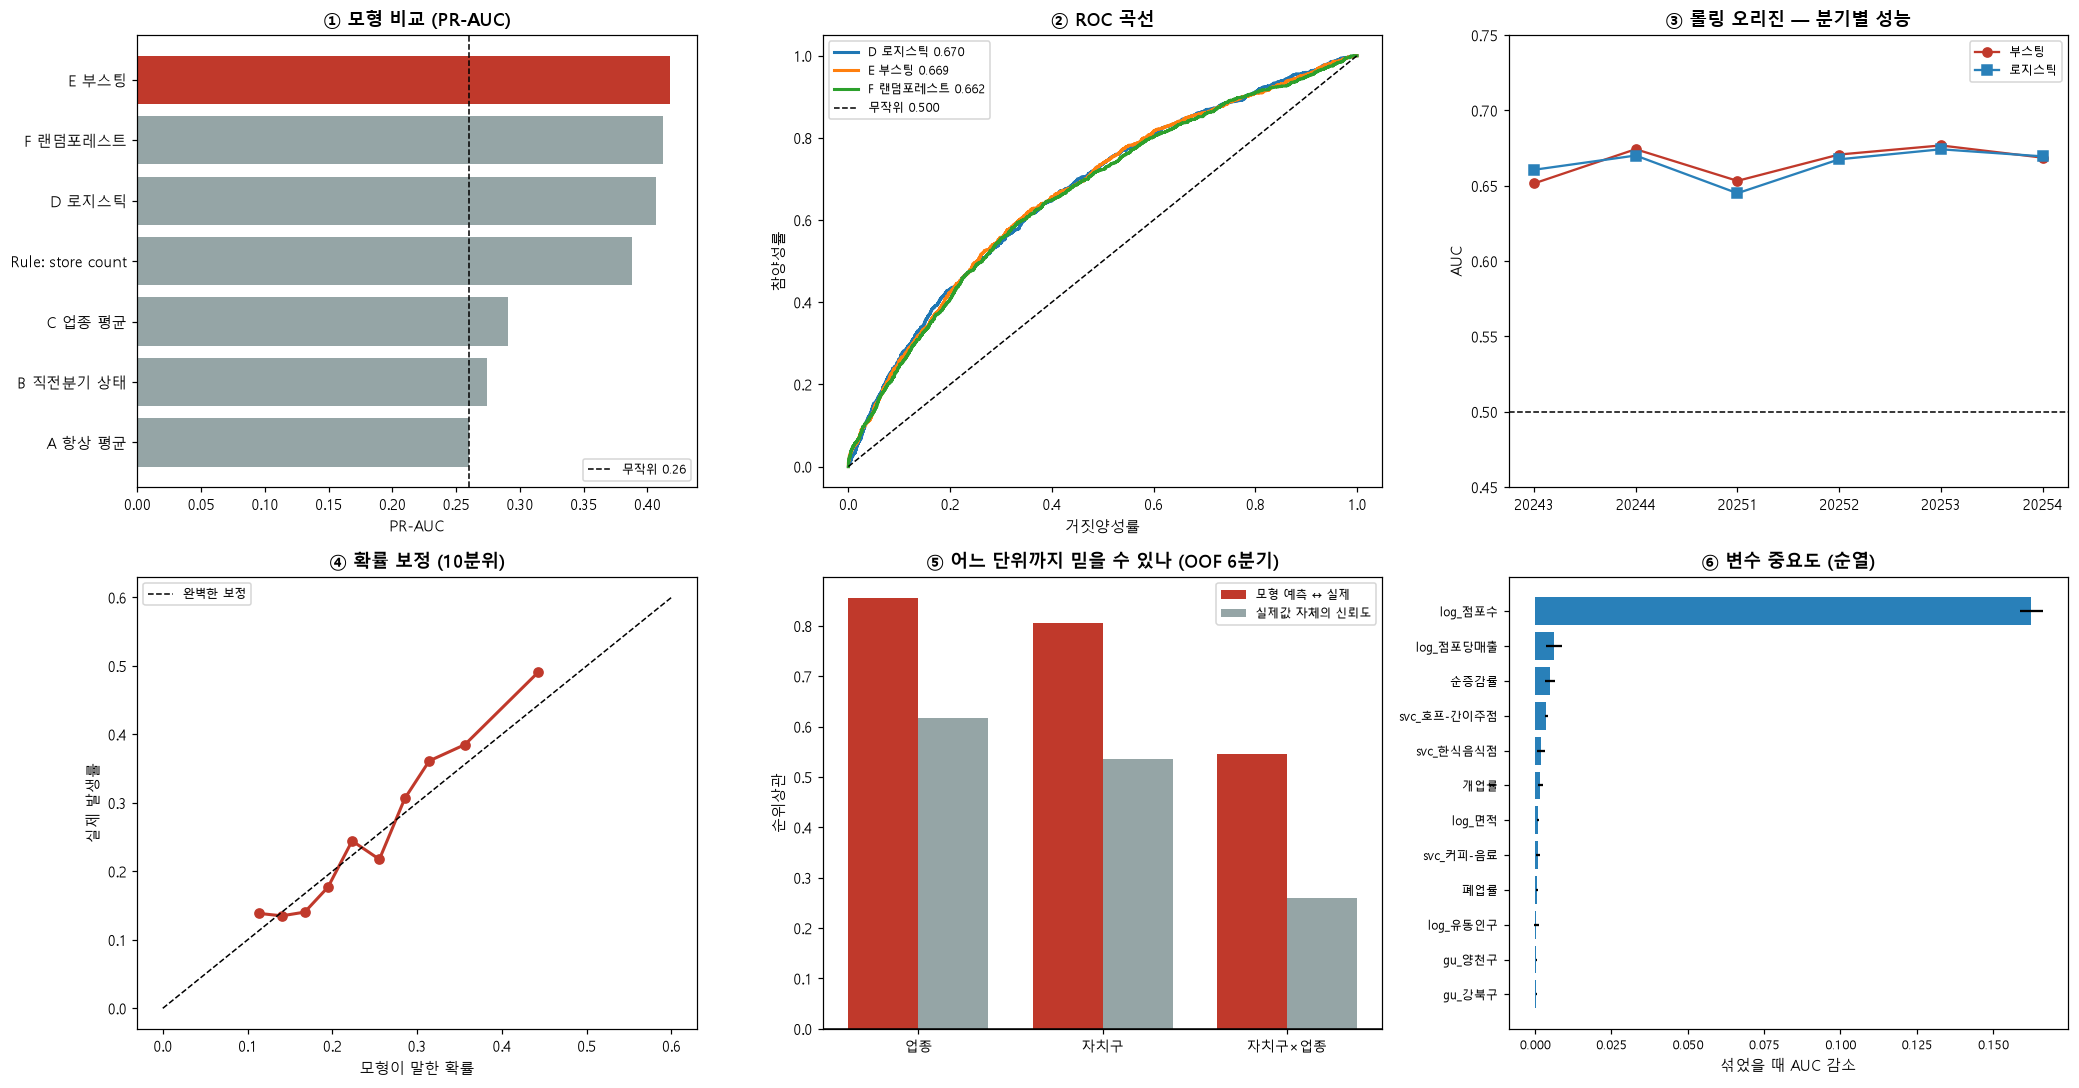

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

# ① 모형 비교
b = board.sort_values("PR-AUC")
cols = ["#c0392b" if i == BEST else "#95a5a6" for i in b.index]
ax[0,0].barh(b.index, b["PR-AUC"], color=cols)
ax[0,0].axvline(yva.mean(), ls="--", c="k", lw=1, label=f"무작위 {yva.mean():.2f}")
ax[0,0].set_xlabel("PR-AUC"); ax[0,0].legend(fontsize=8)
ax[0,0].set_title("① 모형 비교 (PR-AUC)", weight="bold")

# ② ROC
for nm, p in preds.items():
    fpr, tpr, _ = roc_curve(yva, p)
    ax[0,1].plot(fpr, tpr, lw=2, label=f"{nm} {roc_auc_score(yva,p):.3f}")
ax[0,1].plot([0,1],[0,1], ls="--", c="k", lw=1, label="무작위 0.500")
ax[0,1].set_xlabel("거짓양성률"); ax[0,1].set_ylabel("참양성률")
ax[0,1].set_title("② ROC 곡선", weight="bold"); ax[0,1].legend(fontsize=8)

# ③ 롤링 오리진
ax[0,2].plot(rollf["검증분기"].astype(str), rollf["AUC_부스팅"], marker="o", label="부스팅", color="#c0392b")
ax[0,2].plot(rollf["검증분기"].astype(str), rollf["AUC_로지스틱"], marker="s", label="로지스틱", color="#2980b9")
ax[0,2].axhline(0.5, ls="--", c="k", lw=1)
ax[0,2].set_ylim(0.45, 0.75); ax[0,2].set_ylabel("AUC")
ax[0,2].set_title("③ 롤링 오리진 — 분기별 성능", weight="bold"); ax[0,2].legend(fontsize=8)

# ④ 보정
ax[1,0].plot(cal["평균예측"], cal["실제발생률"], marker="o", color="#c0392b", lw=2)
ax[1,0].plot([0,0.6],[0,0.6], ls="--", c="k", lw=1, label="완벽한 보정")
ax[1,0].set_xlabel("모형이 말한 확률"); ax[1,0].set_ylabel("실제 발생률")
ax[1,0].set_title("④ 확률 보정 (10분위)", weight="bold"); ax[1,0].legend(fontsize=8)

# ⑤ 신뢰 가능한 단위
lv = pd.DataFrame(rows_lv)
x = np.arange(len(lv)); w = 0.38
ax[1,1].bar(x - w/2, lv["예측↔실제_순위상관"], w, label="모형 예측 ↔ 실제", color="#c0392b")
ax[1,1].bar(x + w/2, lv["목표_반분신뢰도"], w, label="실제값 자체의 신뢰도", color="#95a5a6")
ax[1,1].set_xticks(x); ax[1,1].set_xticklabels(lv["단위"], fontsize=9)
ax[1,1].set_ylabel("순위상관"); ax[1,1].axhline(0, c="k", lw=1)
ax[1,1].set_title("⑤ 어느 단위까지 믿을 수 있나 (OOF 6분기)", weight="bold")
ax[1,1].legend(fontsize=8)

# ⑥ 변수 중요도
t = imp.head(12).iloc[::-1]
ax[1,2].barh(t["변수"], t["AUC 감소"], xerr=t["표준편차"], color="#2980b9")
ax[1,2].set_xlabel("섞었을 때 AUC 감소"); ax[1,2].tick_params(labelsize=8)
ax[1,2].set_title("⑥ 변수 중요도 (순열)", weight="bold")

plt.tight_layout()
plt.savefig(FIG / "step8_predict.png", dpi=130)
plt.show()

## 8-10. 모델 저장

STEP 9 가 그대로 불러 씁니다. **피처 컬럼 순서와 대치값을 같이 저장**해야 예측 시점에 설계행렬이 어긋나지 않습니다.

In [19]:
bundle = {
    "model": model_best,
    "model_name": BEST,
    "columns": COLS,
    "median": MED,
    "needs_impute": BEST != "E 부스팅",
    "train_quarters": TRAIN_QUARTERS,
    "valid_quarter": VALID_Q,
    "valid_metrics": board.loc[BEST].to_dict(),
    "rolling_auc_mean": float(rollf["AUC_부스팅"].mean()),
}
with open(PROC / "08_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

board.to_csv(OUT / "pred_leaderboard.csv", encoding="utf-8-sig")
rollf.to_csv(OUT / "pred_rolling.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(rows_lv).to_csv(OUT / "pred_reliability.csv", index=False, encoding="utf-8-sig")
oof.to_pickle(PROC / "08_oof.pkl")

print(f"[저장] 08_model.pkl   ({BEST}, 피처 {len(COLS)}개)")
print(f"[저장] 08_oof.pkl     {oof.shape}")
print(f"[저장] outputs/pred_leaderboard.csv, pred_rolling.csv, pred_reliability.csv")
print(f"[저장] figures/step8_predict.png\n")

print("── STEP 9 로 넘길 것 ─────────────────")
print(f"  선택 모형   : {BEST}")
print(f"  [검증값] AUC {board.loc[BEST,'AUC']:.3f} / PR-AUC {board.loc[BEST,'PR-AUC']:.3f} "
      f"(무작위 {yva.mean():.3f}) / Brier {board.loc[BEST,'Brier']:.3f}")
print( "     ⚠️ 이 표를 보고 모델을 골랐으므로 낙관 쪽으로 치우친 값입니다.")
print(f"  [편향 없는 추정] 롤링 AUC {rollf['AUC_부스팅'].mean():.3f} ± {rollf['AUC_부스팅'].std():.3f} "
      f"({len(rollf)}개 분기)  ← 보고에는 이 값을 쓰세요")
print(f"  [실무 성능] 상위 {topk.index[0]}칸 정밀도 {topk['모델 정밀도'].iloc[0]:.3f} "
      f"(점포수 규칙 {topk['점포수 정밀도'].iloc[0]:.3f}, 목록 겹침 {topk['두 목록 겹침'].iloc[0]:.0%})")
print(f"  [외부 기준선] 서울시 상권변화지표 HL  Lift {prec_hl/base_rate:.3f}")
print(f"  신뢰 단위   : 업종·자치구 순위는 신뢰 가능, 자치구×업종은 확률+표본수 병기 필요")

[저장] 08_model.pkl   (E 부스팅, 피처 51개)
[저장] 08_oof.pkl     (33223, 7)
[저장] outputs/pred_leaderboard.csv, pred_rolling.csv, pred_reliability.csv
[저장] figures/step8_predict.png

── STEP 9 로 넘길 것 ─────────────────
  선택 모형   : E 부스팅
  [검증값] AUC 0.669 / PR-AUC 0.418 (무작위 0.260) / Brier 0.179
     ⚠️ 이 표를 보고 모델을 골랐으므로 낙관 쪽으로 치우친 값입니다.
  [편향 없는 추정] 롤링 AUC 0.666 ± 0.011 (6개 분기)  ← 보고에는 이 값을 쓰세요
  [실무 성능] 상위 50칸 정밀도 0.780 (점포수 규칙 0.380, 목록 겹침 4%)
  [외부 기준선] 서울시 상권변화지표 HL  Lift 0.937
  신뢰 단위   : 업종·자치구 순위는 신뢰 가능, 자치구×업종은 확률+표본수 병기 필요


---

## STEP 9 에서 할 일

- `03_score.pkl`(피처 20261)에 확률을 매겨 **20262 예측** 산출
- **자치구 × 업종** 순위표 — 확률·표본 수·불확실성을 함께 표기
- 칸이 얇은 조합은 순위에서 빼고 그 사실을 명시
- H2 결과와 나란히 배치 — "규모를 맞추면 한식이 안전"(인과) vs "현실에서는 한식이 위험 상위"(예측) 는 모순이 아니라 서로 다른 질문의 답
